In [1]:
library(ggrepel)
library(dplyr)
setwd('../../thp1-k562-lps.hg38.rep/intmd/sc_to_tradeSeq/')

Loading required package: ggplot2


Attaching package: 'dplyr'


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




In [58]:
plot_association_volcano <- function(
  asso_df,

  # ---------- condition display names ----------
  condition_key = c(
    condA = "Condition A",
    condB = "Condition B"
  ),

  # ---------- thresholds ----------
  fdr_thresh        = 0.01,
  require_fdr       = TRUE,
  dyn_thresh_condA  = 0.75,
  flat_thresh_condA = 0.25,
  dyn_thresh_condB  = 0.75,
  flat_thresh_condB = 0.25,

  # ---------- plotting ----------
  wald_mode         = c("max", "difference"),
  point_alpha       = 0.95,
  point_size        = 2.2,
  axis_title_size   = 26,
  axis_text_size    = 18,
  legend_text_size  = 16,
  axis_title_pad_x  = 12,
  axis_title_pad_y  = 12,
  y_log_floor       = 1e-6,
  x_lim             = NULL,
  y_lim             = NULL,
  y_break           = NULL,
  y_break_quantile  = 0.95,
  y_lower_scale     = 0.35,

  # ---------- labels ----------
  top_labels        = 12,
  label_size        = 4.6,
  label_only_pass   = FALSE,
  label_rank_by     = c("wald", "x"),
  label_top_wald    = NULL,
  label_top_condA   = NULL,
  label_top_condB   = NULL,

  # ---------- ggrepel controls ----------
  repel_box_padding        = 0.25,
  repel_point_padding      = 0.20,
  repel_min_segment_length = 0,
  repel_force              = 1.2,
  repel_max_overlaps       = Inf,
  repel_seed               = 1,

  # ---------- optional legend-label overrides ----------
  lab_condA_ind = NULL,
  lab_condA_rep = NULL,
  lab_condB_ind = NULL,
  lab_condB_rep = NULL,

  # ---------- colors ----------
  col_condA_ind = "#E35335",
  col_condA_rep = "#FFE5B4",
  col_condB_ind = "#008000",
  col_condB_rep = "#90EE90",

  col_sigmid = "#6E6E6E",
  col_other  = "#B8B8B8",
  col_line   = "#6E6E6E",

  # ---------- legend ----------
  legend_pos      = c(0.03, 0.05),
  legend_just     = c(0, 0),
  legend_bg_alpha = 0.75,
  legend_bg_col   = "white",
  legend_key_size = 0.8,

  save_prefix = NULL
) {
  label_rank_by <- match.arg(label_rank_by)
  wald_mode <- match.arg(wald_mode)

  required_cols <- c(
    "waldStat_1", "waldStat_2", "qval",
    "log2FC_t1", "log2FC_t2"
  )

  stopifnot(all(required_cols %in% names(asso_df)))

  if (!all(c("condA", "condB") %in% names(condition_key))) {
    stop(
      "condition_key must be a named vector containing ",
      "'condA' and 'condB'."
    )
  }

  condA_name <- as.character(condition_key[["condA"]])
  condB_name <- as.character(condition_key[["condB"]])

  # Construct legend labels unless explicitly overridden
  if (is.null(lab_condA_ind)) {
    lab_condA_ind <- paste0(condA_name, "-specific induction")
  }

  if (is.null(lab_condA_rep)) {
    lab_condA_rep <- paste0(condA_name, "-specific repression")
  }

  if (is.null(lab_condB_ind)) {
    lab_condB_ind <- paste0(condB_name, "-specific induction")
  }

  if (is.null(lab_condB_rep)) {
    lab_condB_rep <- paste0(condB_name, "-specific repression")
  }

  x_axis_label <- sprintf(
    "Response specificity (|log2FC(%s)| - |log2FC(%s)|)",
    condA_name,
    condB_name
  )

  y_axis_label <- switch(
    wald_mode,
    max = expression(log[10]("Maximum Wald")),
    difference = expression(log[10]("Wald difference"))
  )

  df <- asso_df

  if (!requireNamespace("ggrepel", quietly = TRUE)) {
    stop(
      "Package 'ggrepel' is required. ",
      "Install via install.packages('ggrepel')."
    )
  }

  # ---------- condition mapping ----------
  # t1 = condA; t2 = condB
  condA_eff <- as.numeric(df$log2FC_t1)
  condB_eff <- as.numeric(df$log2FC_t2)

  # Right side means condA is more dynamic
  x_raw <- abs(condA_eff) - abs(condB_eff)

  # ---------- Wald metric ----------
  wald_1 <- as.numeric(df$waldStat_1)
  wald_2 <- as.numeric(df$waldStat_2)

  if (wald_mode == "max") {
    y_raw <- pmax(wald_1, wald_2, na.rm = TRUE)
    y_raw[!is.finite(y_raw)] <- NA_real_
  } else {
    # Higher Wald minus lower Wald
    y_raw <- ifelse(
      is.finite(wald_1) & is.finite(wald_2),
      abs(wald_1 - wald_2),
      NA_real_
    )
  }

  q_raw <- as.numeric(df$qval)

  pass_fdr <- is.finite(q_raw) & q_raw < fdr_thresh

  pass_gate <- if (isTRUE(require_fdr)) {
    pass_fdr
  } else {
    rep(TRUE, nrow(df))
  }

  # ---------- clamp y ----------
  y_plot <- ifelse(
    is.finite(y_raw),
    pmax(y_raw, y_log_floor),
    y_log_floor
  )

  if (!is.null(y_lim) && length(y_lim) == 2) {
    if (is.finite(y_lim[1])) {
      y_plot <- pmax(
        y_plot,
        max(y_log_floor, y_lim[1])
      )
    }

    if (is.finite(y_lim[2])) {
      y_plot <- pmin(y_plot, y_lim[2])
    }
  }

  # ---------- clamp x ----------
  x_plot <- x_raw

  if (
    !is.null(x_lim) &&
    length(x_lim) == 2 &&
    all(is.finite(x_lim))
  ) {
    xmin <- min(x_lim)
    xmax <- max(x_lim)
    msk <- is.finite(x_plot)

    x_plot[msk] <- pmin(
      pmax(x_plot[msk], xmin),
      xmax
    )
  }

  df$x_plot <- x_plot
  df$y_plot <- y_plot

  # ---------- specificity and direction ----------
  a_dyn <- is.finite(condA_eff) &
    abs(condA_eff) >= dyn_thresh_condA

  a_flat <- is.finite(condA_eff) &
    abs(condA_eff) <= flat_thresh_condA

  b_dyn <- is.finite(condB_eff) &
    abs(condB_eff) >= dyn_thresh_condB

  b_flat <- is.finite(condB_eff) &
    abs(condB_eff) <= flat_thresh_condB

  condA_spec <- pass_gate & a_dyn & b_flat
  condB_spec <- pass_gate & b_dyn & a_flat

  a_pos <- is.finite(condA_eff) & condA_eff > 0
  a_neg <- is.finite(condA_eff) & condA_eff < 0
  b_pos <- is.finite(condB_eff) & condB_eff > 0
  b_neg <- is.finite(condB_eff) & condB_eff < 0

  side <- rep("other", nrow(df))
  side[pass_fdr] <- "sig_mid"

  side[condA_spec & a_pos] <- "condA_ind"
  side[condA_spec & a_neg] <- "condA_rep"
  side[condB_spec & b_pos] <- "condB_ind"
  side[condB_spec & b_neg] <- "condB_rep"

  df$side <- factor(
    side,
    levels = c(
      "other",
      "sig_mid",
      "condA_ind",
      "condA_rep",
      "condB_ind",
      "condB_rep"
    )
  )

  # ---------- label selection ----------
  df$label <- ""

  rn <- rownames(df)

  gene_names <- if (!is.null(rn)) {
    rn
  } else if ("gene" %in% names(df)) {
    as.character(df$gene)
  } else {
    as.character(seq_len(nrow(df)))
  }

  pass_side <- if (label_only_pass) {
    df$side %in% c(
      "condA_ind",
      "condA_rep",
      "condB_ind",
      "condB_rep"
    )
  } else {
    rep(TRUE, nrow(df))
  }

  labs_idx <- integer(0)

  if (!is.null(label_top_wald) && as.integer(label_top_wald) > 0) {
    cand <- which(is.finite(y_raw) & pass_side)

    if (length(cand)) {
      ord <- cand[
        order(
          y_raw[cand],
          abs(x_raw[cand]),
          decreasing = TRUE
        )
      ]

      labs_idx <- c(
        labs_idx,
        head(ord, as.integer(label_top_wald))
      )
    }
  }

  if (!is.null(label_top_condA) && as.integer(label_top_condA) > 0) {
    cand <- which(
      df$side %in% c("condA_ind", "condA_rep") &
        pass_side &
        is.finite(condA_eff) &
        is.finite(y_raw)
    )

    if (length(cand)) {
      ord <- cand[
        order(
          abs(condA_eff[cand]),
          y_raw[cand],
          decreasing = TRUE
        )
      ]

      labs_idx <- c(
        labs_idx,
        head(ord, as.integer(label_top_condA))
      )
    }
  }

  if (!is.null(label_top_condB) && as.integer(label_top_condB) > 0) {
    cand <- which(
      df$side %in% c("condB_ind", "condB_rep") &
        pass_side &
        is.finite(condB_eff) &
        is.finite(y_raw)
    )

    if (length(cand)) {
      ord <- cand[
        order(
          abs(condB_eff[cand]),
          y_raw[cand],
          decreasing = TRUE
        )
      ]

      labs_idx <- c(
        labs_idx,
        head(ord, as.integer(label_top_condB))
      )
    }
  }

  if (length(labs_idx) == 0 && top_labels > 0) {
    rank_val <- if (label_rank_by == "wald") {
      y_raw
    } else {
      x_raw
    }

    cand <- which(
      is.finite(rank_val) & pass_side
    )

    if (length(cand)) {
      ord <- cand[
        order(
          rank_val[cand],
          y_raw[cand],
          decreasing = TRUE
        )
      ]

      labs_idx <- head(
        ord,
        as.integer(top_labels)
      )
    }
  }

  labs_idx <- unique(labs_idx)
  df$label[labs_idx] <- gene_names[labs_idx]

  label_df <- df[
    df$label != "" &
      is.finite(df$x_plot) &
      is.finite(df$y_plot),
    ,
    drop = FALSE
  ]

  # ---------- piecewise y scaling ----------
  logy <- log10(df$y_plot)

  if (is.null(y_break) || !is.finite(y_break)) {
    non_sig <- df$y_plot[
      !pass_fdr & is.finite(df$y_plot)
    ]

    y_break <- if (length(non_sig)) {
      as.numeric(
        stats::quantile(
          non_sig,
          probs = y_break_quantile,
          na.rm = TRUE
        )
      )
    } else {
      as.numeric(
        stats::quantile(
          df$y_plot,
          probs = 0.60,
          na.rm = TRUE
        )
      )
    }
  }

  y_break <- max(y_break, y_log_floor)
  t_break <- log10(y_break)

  y_lower_scale <- max(
    1e-6,
    min(1, y_lower_scale)
  )

  ps <- function(t) {
    ifelse(
      t <= t_break,
      y_lower_scale * t,
      y_lower_scale * t_break + (t - t_break)
    )
  }

  df$y_scaled <- ps(log10(df$y_plot))

  t_lo <- if (!is.null(y_lim) && is.finite(y_lim[1])) {
    log10(max(y_log_floor, y_lim[1]))
  } else {
    min(logy[is.finite(logy)])
  }

  t_hi <- if (!is.null(y_lim) && is.finite(y_lim[2])) {
    log10(y_lim[2])
  } else {
    max(logy[is.finite(logy)])
  }

  y_limits_scaled <- ps(c(t_lo, t_hi))

  tick_t <- seq(
    floor(t_lo),
    ceiling(t_hi),
    by = 1
  )

  tick_pos <- ps(tick_t)
  tick_lab <- as.character(tick_t)

  label_df$y_scaled <- ps(
    log10(label_df$y_plot)
  )

  # ---------- colors ----------
  col_map <- c(
    other     = col_other,
    sig_mid   = col_sigmid,
    condA_ind = col_condA_ind,
    condA_rep = col_condA_rep,
    condB_ind = col_condB_ind,
    condB_rep = col_condB_rep
  )

  # ---------- plot ----------
  p <- ggplot2::ggplot(
    df,
    ggplot2::aes(
      x = x_plot,
      y = y_scaled
    )
  ) +
    ggplot2::geom_point(
      ggplot2::aes(colour = side),
      shape = 16,
      alpha = point_alpha,
      size = point_size,
      show.legend = TRUE
    ) +
    ggplot2::scale_colour_manual(
      values = col_map,
      breaks = c(
        "condA_ind",
        "condA_rep",
        "condB_ind",
        "condB_rep"
      ),
      labels = c(
        lab_condA_ind,
        lab_condA_rep,
        lab_condB_ind,
        lab_condB_rep
      ),
      drop = FALSE,
      name = NULL
    ) +
    ggplot2::geom_vline(
      xintercept = 0,
      linetype = "solid",
      linewidth = 0.6,
      color = col_line
    ) +
    ggplot2::scale_x_continuous(
      limits = if (
        !is.null(x_lim) &&
        length(x_lim) == 2
      ) {
        c(min(x_lim), max(x_lim))
      } else {
        NULL
      }
    ) +
    ggplot2::scale_y_continuous(
      limits = y_limits_scaled,
      breaks = tick_pos,
      labels = tick_lab
    ) +
    ggplot2::labs(
      x = x_axis_label,
      y = y_axis_label
    ) +
    ggplot2::theme_classic(
      base_size = 20
    ) +
    ggplot2::theme(
      panel.grid.major.y = ggplot2::element_line(
        color = "grey85",
        linewidth = 0.4
      ),
      panel.grid.minor.y = ggplot2::element_blank(),
      axis.title.x = ggplot2::element_text(
        size = axis_title_size,
        margin = ggplot2::margin(
          t = axis_title_pad_x
        )
      ),
      axis.title.y = ggplot2::element_text(
        size = axis_title_size,
        face = "bold",
        margin = ggplot2::margin(
          r = axis_title_pad_y
        )
      ),
      axis.text = ggplot2::element_text(
        size = axis_text_size
      ),
      plot.margin = ggplot2::margin(
        14, 18, 14, 16
      ),
      legend.position = legend_pos,
      legend.justification = legend_just,
      legend.background = ggplot2::element_rect(
        fill = scales::alpha(
          legend_bg_col,
          legend_bg_alpha
        ),
        color = "grey60",
        linewidth = 0.3
      ),
      legend.key = ggplot2::element_rect(
        fill = NA,
        color = NA
      ),
      legend.key.size = ggplot2::unit(
        legend_key_size,
        "lines"
      ),
      legend.text = ggplot2::element_text(
        size = legend_text_size
      )
    )

  # ---------- ggrepel labels ----------
  if (nrow(label_df) > 0) {
    p <- p +
      ggrepel::geom_label_repel(
        data = label_df,
        ggplot2::aes(
          x = x_plot,
          y = y_scaled,
          label = label
        ),
        inherit.aes = FALSE,
        size = label_size,
        label.size = 0.15,
        label.padding = ggplot2::unit(
          0.10,
          "lines"
        ),
        fill = scales::alpha(
          "white",
          0.75
        ),
        color = "black",
        box.padding = ggplot2::unit(
          repel_box_padding,
          "lines"
        ),
        point.padding = ggplot2::unit(
          repel_point_padding,
          "lines"
        ),
        min.segment.length = repel_min_segment_length,
        force = repel_force,
        max.overlaps = repel_max_overlaps,
        seed = repel_seed
      )
  }

  if (!is.null(save_prefix)) {
    ggplot2::ggsave(
      paste0(save_prefix, ".png"),
      p,
      width = 10,
      height = 8.75,
      dpi = 300
    )

    ggplot2::ggsave(
      paste0(save_prefix, ".pdf"),
      p,
      width = 10,
      height = 8.75,
      dpi = 300
    )
  }

  p
}

In [43]:
make_combined_from_pc_df <- function(
  pc_df,
  query_cell_type_1,
  query_cell_type_2,
  gene_col = "gene",
  cell_type_col = "cell_type",
  wald_col = "waldStat_1",
  log2fc_col = "peak_log2fc",
  qval_col = "qval_1",
  qval_fun = pmax,          # conservative shared q-value by default
  keep_only_common = TRUE,
  fill_missing = FALSE,     # NEW: fill missing genes with null values
  arrange_by_wald_1 = TRUE
) {
  library(dplyr)
  library(tidyr)

  df1 <- pc_df %>%
    filter(.data[[cell_type_col]] == query_cell_type_1) %>%
    select(
      gene = all_of(gene_col),
      pvalue_1 = all_of("pvalue_1"),
      waldStat_1 = all_of(wald_col),
      log2FC_t1 = all_of(log2fc_col),
      qval_1_tmp = all_of(qval_col)
    )

  df2 <- pc_df %>%
    filter(.data[[cell_type_col]] == query_cell_type_2) %>%
    select(
      gene = all_of(gene_col),
      pvalue_2 = all_of("pvalue_1"),
      waldStat_2 = all_of(wald_col),
      log2FC_t2 = all_of(log2fc_col),
      qval_2_tmp = all_of(qval_col)
    )

  # If fill_missing = TRUE, retain the union of genes regardless of
  # keep_only_common and fill the missing context with null values.
  if (fill_missing) {

    combined <- full_join(df1, df2, by = "gene") %>%
      mutate(
        # missing in cell type 1
        waldStat_1 = replace_na(waldStat_1, 0),
        log2FC_t1  = replace_na(log2FC_t1, 0),
        qval_1_tmp = replace_na(qval_1_tmp, 1),
        pvalue_1   = replace_na(pvalue_1, 1),

        # missing in cell type 2
        waldStat_2 = replace_na(waldStat_2, 0),
        log2FC_t2  = replace_na(log2FC_t2, 0),
        qval_2_tmp = replace_na(qval_2_tmp, 1),
        pvalue_2   = replace_na(pvalue_2, 1)
      )

  } else {

    combined <- if (keep_only_common) {
      inner_join(df1, df2, by = "gene")
    } else {
      full_join(df1, df2, by = "gene")
    }
  }

  combined <- combined %>%
    mutate(
      qval = qval_fun(qval_1_tmp, qval_2_tmp, na.rm = TRUE)
    ) %>%
    select(
      gene,
      waldStat_1,
      waldStat_2,
      qval,
      log2FC_t1,
      log2FC_t2,
      pvalue_1,
      pvalue_2
    )

  if (arrange_by_wald_1) {
    combined <- combined %>%
      arrange(desc(waldStat_1))
  }

  combined <- as.data.frame(combined)
  rownames(combined) <- combined$gene
  combined$gene <- NULL

  combined
}

In [17]:
pc_df = readRDS('../../../k562-tnfa-puromycin.hg38/intmd/global_analysis/extended/pc_df.rds')
pc_df = pc_df %>% select(gene, cell_type, peak_log2fc, waldStat_1, pvalue_1, qval_1) 
dim(pc_df)

[1] 14219     6

In [117]:
excl_genes = list()
excl_genes[['K562a']] = unique(c(read.csv('../../../k562-tnfa.hg38.rep/notebooks/exclude_time-tag-bias_genes.csv')$X0, read.csv('../../../k562-tnfa.hg38.rep/notebooks/exclude_low-count-genes.k562.csv')$X0))
excl_genes[['K562b']] = unique(c(read.csv('../../../thp1-k562-lps.hg38.rep/notebooks/exclude_time-tag-bias_genes.k562.csv')$X0, read.csv('../../../thp1-k562-lps.hg38.rep/notebooks/exclude_low-count-genes.k562.csv')$X0))
excl_genes[['THP1']] = unique(c(read.csv('../../../thp1-k562-lps.hg38.rep/notebooks/exclude_time-tag-bias_genes.thp1.csv')$X0, read.csv('../../../thp1-k562-lps.hg38.rep/notebooks/exclude_low-count-genes.thp1.csv')$X0))
excl_genes[['K562_puro']] = unique(c(read.csv('../../../k562-tnfa-puromycin.hg38/notebooks/exclude_time-tag-bias_genes.csv')$X0, read.csv('../../../k562-tnfa-puromycin.hg38/notebooks/exclude_low-count-genes.k562.csv')$X0))

length(excl_genes[['K562a']] )
length(excl_genes[['K562b']] )
length(excl_genes[['THP1']] )
length(excl_genes[['K562_puro']] )

for (query_cell_type in names(excl_genes)) {
    print(query_cell_type)
    print(length(intersect((pc_df %>% filter(cell_type == query_cell_type))$gene, excl_genes[[query_cell_type]])))
}

excl_rownames = c(paste0(excl_genes[['K562a']], '_K562a'), paste0(excl_genes[['K562b']], '_K562b'), paste0(excl_genes[['THP1']], '_THP1'), paste0(excl_genes[['K562_puro']], 'K562_puro'))
excl_rownames = intersect(excl_rownames, rownames(pc_df))
pc_df <- pc_df[!rownames(pc_df) %in% excl_rownames,]
dim(pc_df)

[1] 3433

[1] 7917

[1] 10987

[1] 3209

[1] "K562a"
[1] 0
[1] "K562b"
[1] 0
[1] "THP1"
[1] 0
[1] "K562_puro"
[1] 0


[1] 14219     6

In [122]:
# desc = readRDS('../../../k562-tnfa-puromycin.hg38/intmd/global_analysis/extended/desc.pc_1e-1.rds')
desc = readRDS('../../../k562-tnfa-puromycin.hg38/intmd/global_analysis/extended/desc.pc_1e-1.rds')
pc_df$peak_log2fc = desc[rownames(pc_df), ]$peak_log2fc

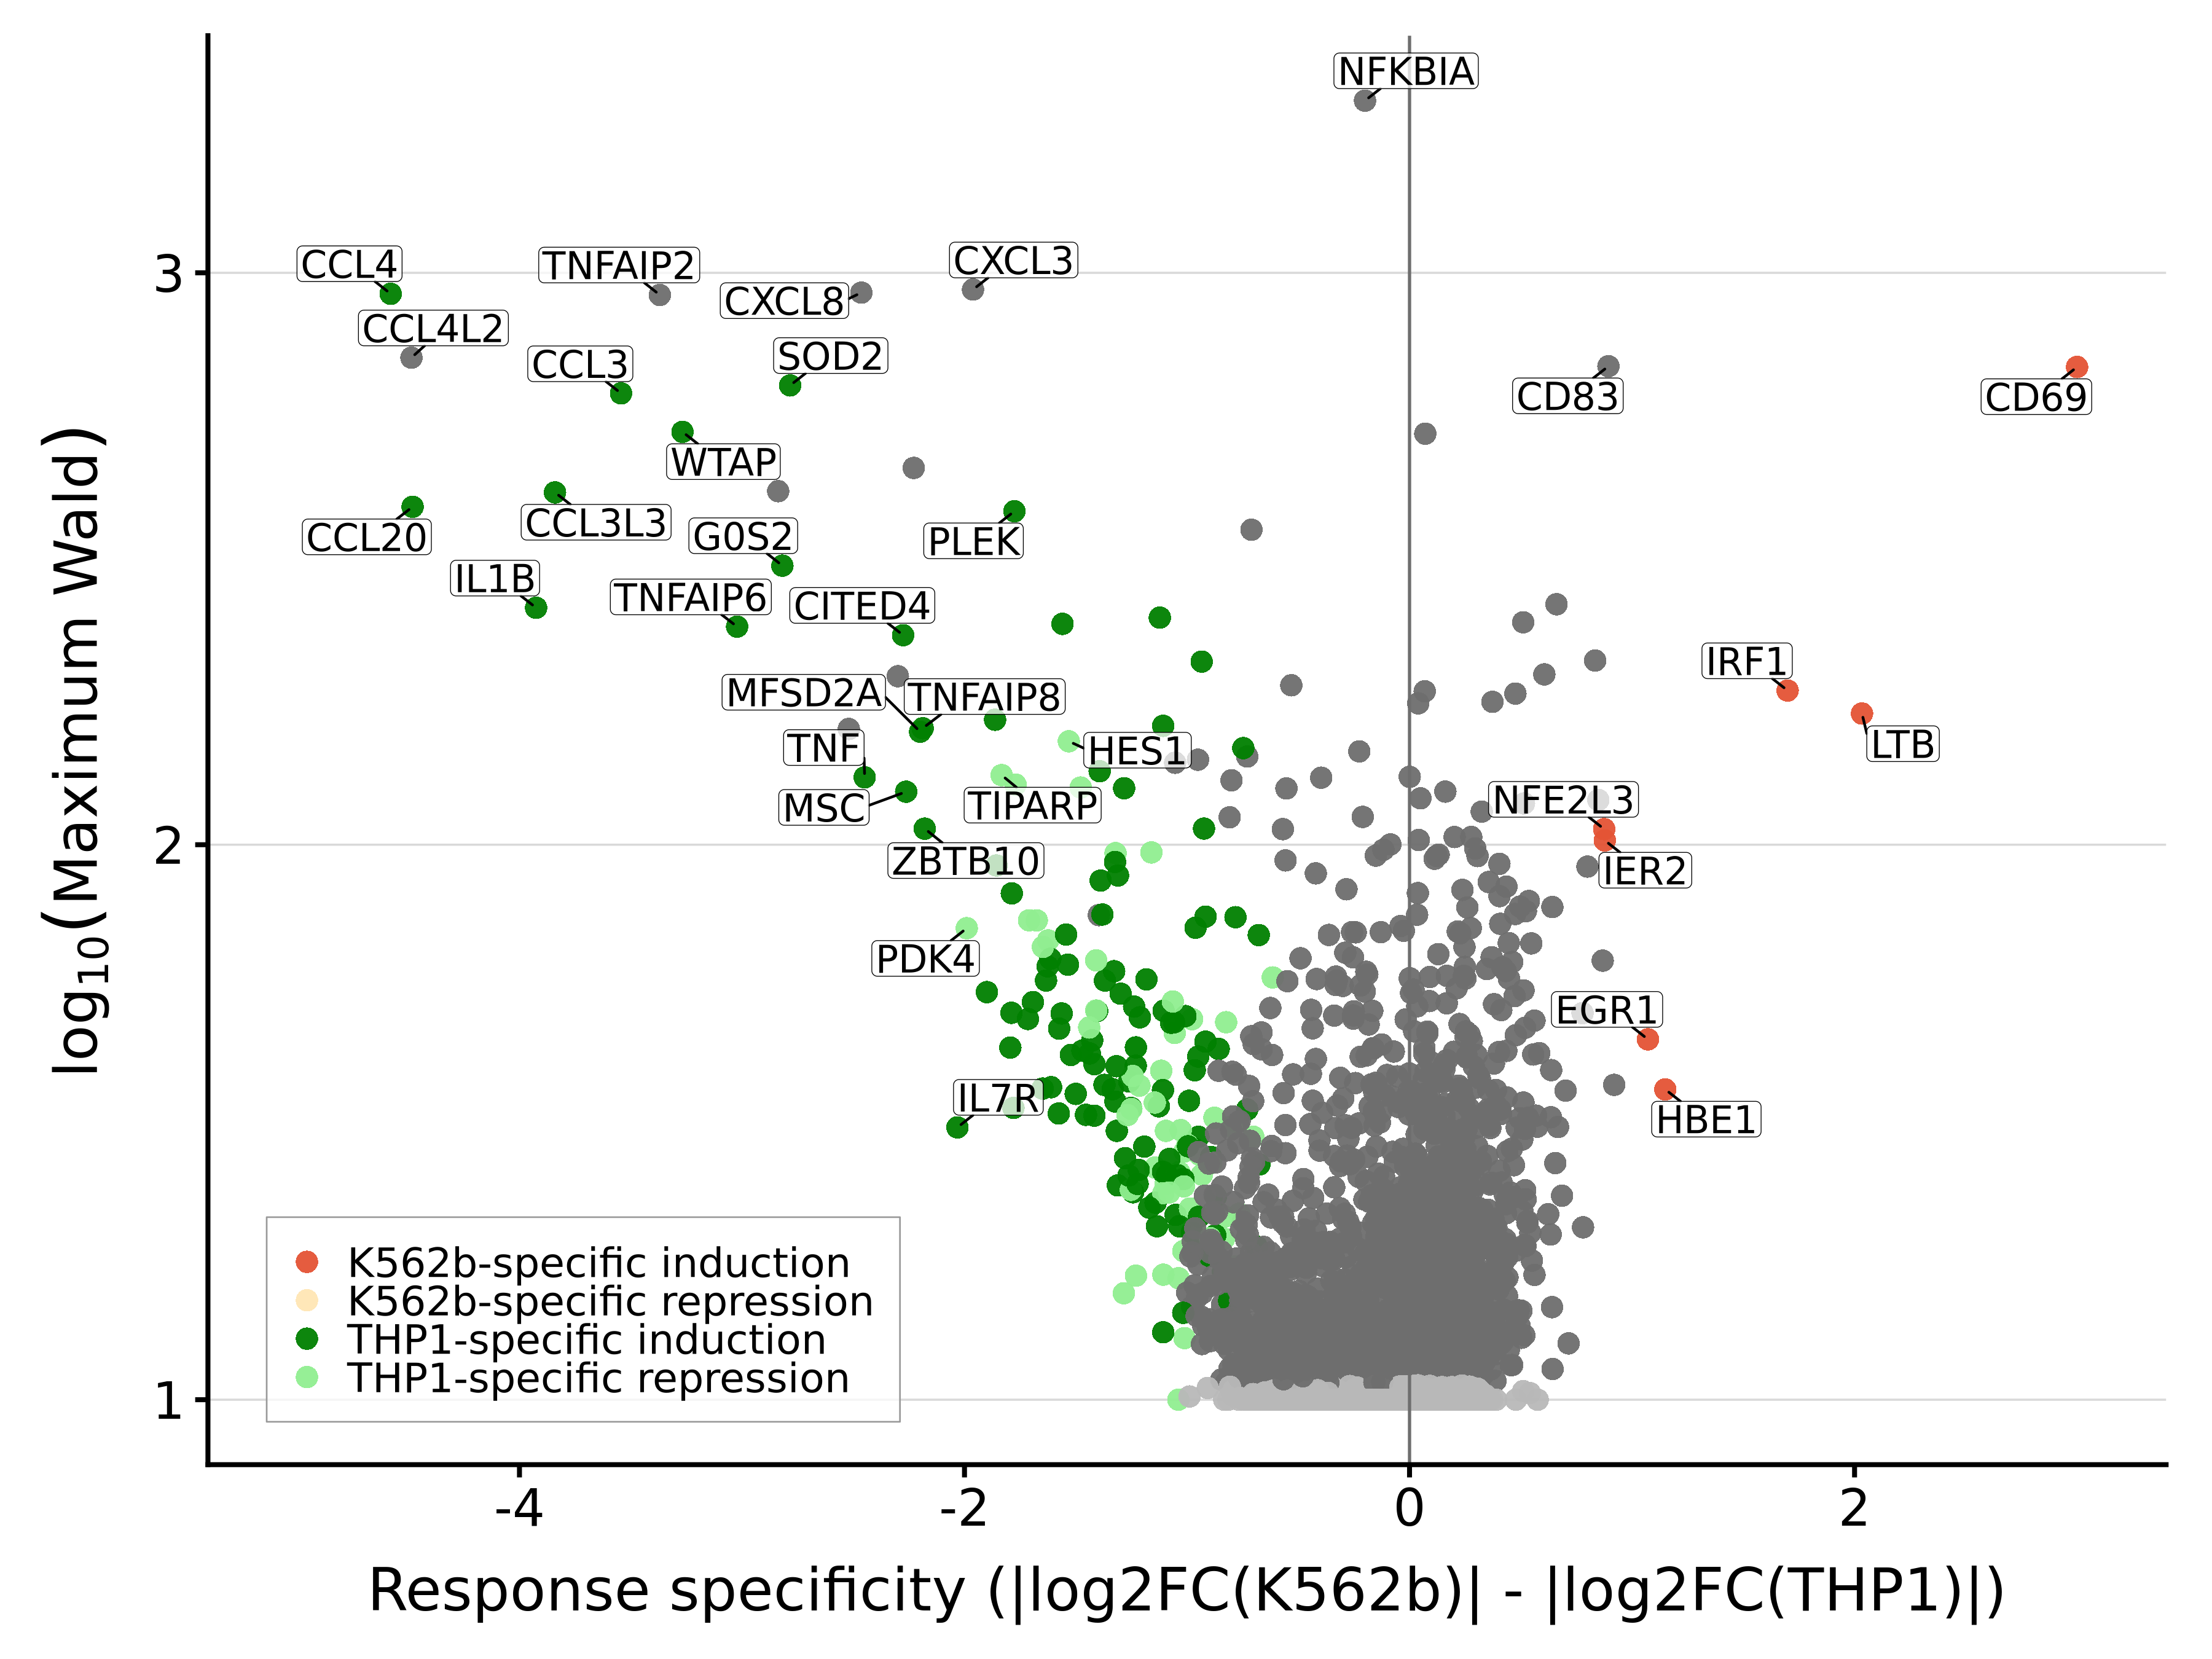

In [128]:
combined <- make_combined_from_pc_df(pc_df, 
                                     query_cell_type_1 = "K562b", 
                                     query_cell_type_2 = "THP1", 
                                     qval_fun = pmin,
                                     keep_only_common = FALSE,
                                     fill_missing = TRUE)

# combined %>% select(waldStat_1, waldStat_2, qval, log2FC_t1, log2FC_t2) %>% arrange(desc(waldStat_1))
combined = combined %>% mutate(qval = pmin(pvalue_1, pvalue_2, na.rm = TRUE))

options(repr.plot.width = 12, repr.plot.height = 9, repr.plot.res = 300)

dyn_thresh  <- 1
flat_thresh <- 0.5

p <- plot_association_volcano(
  combined %>% filter(qval < 0.05),
  require_fdr      = FALSE,  # set TRUE for strict gating
  fdr_thresh       = 0.01,
  dyn_thresh_condA  = dyn_thresh,
  flat_thresh_condA = flat_thresh,
  dyn_thresh_condB  = dyn_thresh,
  flat_thresh_condB = flat_thresh,

  condition_key = c(
    condA = "K562b",
    condB = "THP1"
  ),
    
  x_lim = c(-5, 3),
  y_lim = c(10, 2000),
  label_top_wald = 10,
  label_top_condA = 20,
  label_top_condB = 20,
  label_size = 5.2,
  axis_title_size = 23,
  axis_text_size  = 20,
  legend_text_size = 16,
  point_size = 3.5,
  # legend placement inside bottom-left
  legend_pos  = c(0.03, 0.03),
  legend_just = c(0, 0),
  # ggrepel tuning
  repel_force = 1.4,
  repel_box_padding = 0.25,
  repel_point_padding = 0.10,
  repel_max_overlaps = Inf,
  repel_seed = 7,
  save_prefix = "../../figures/THP1vsK562_ResponseSpecificityVolcanoPlot"
)
p

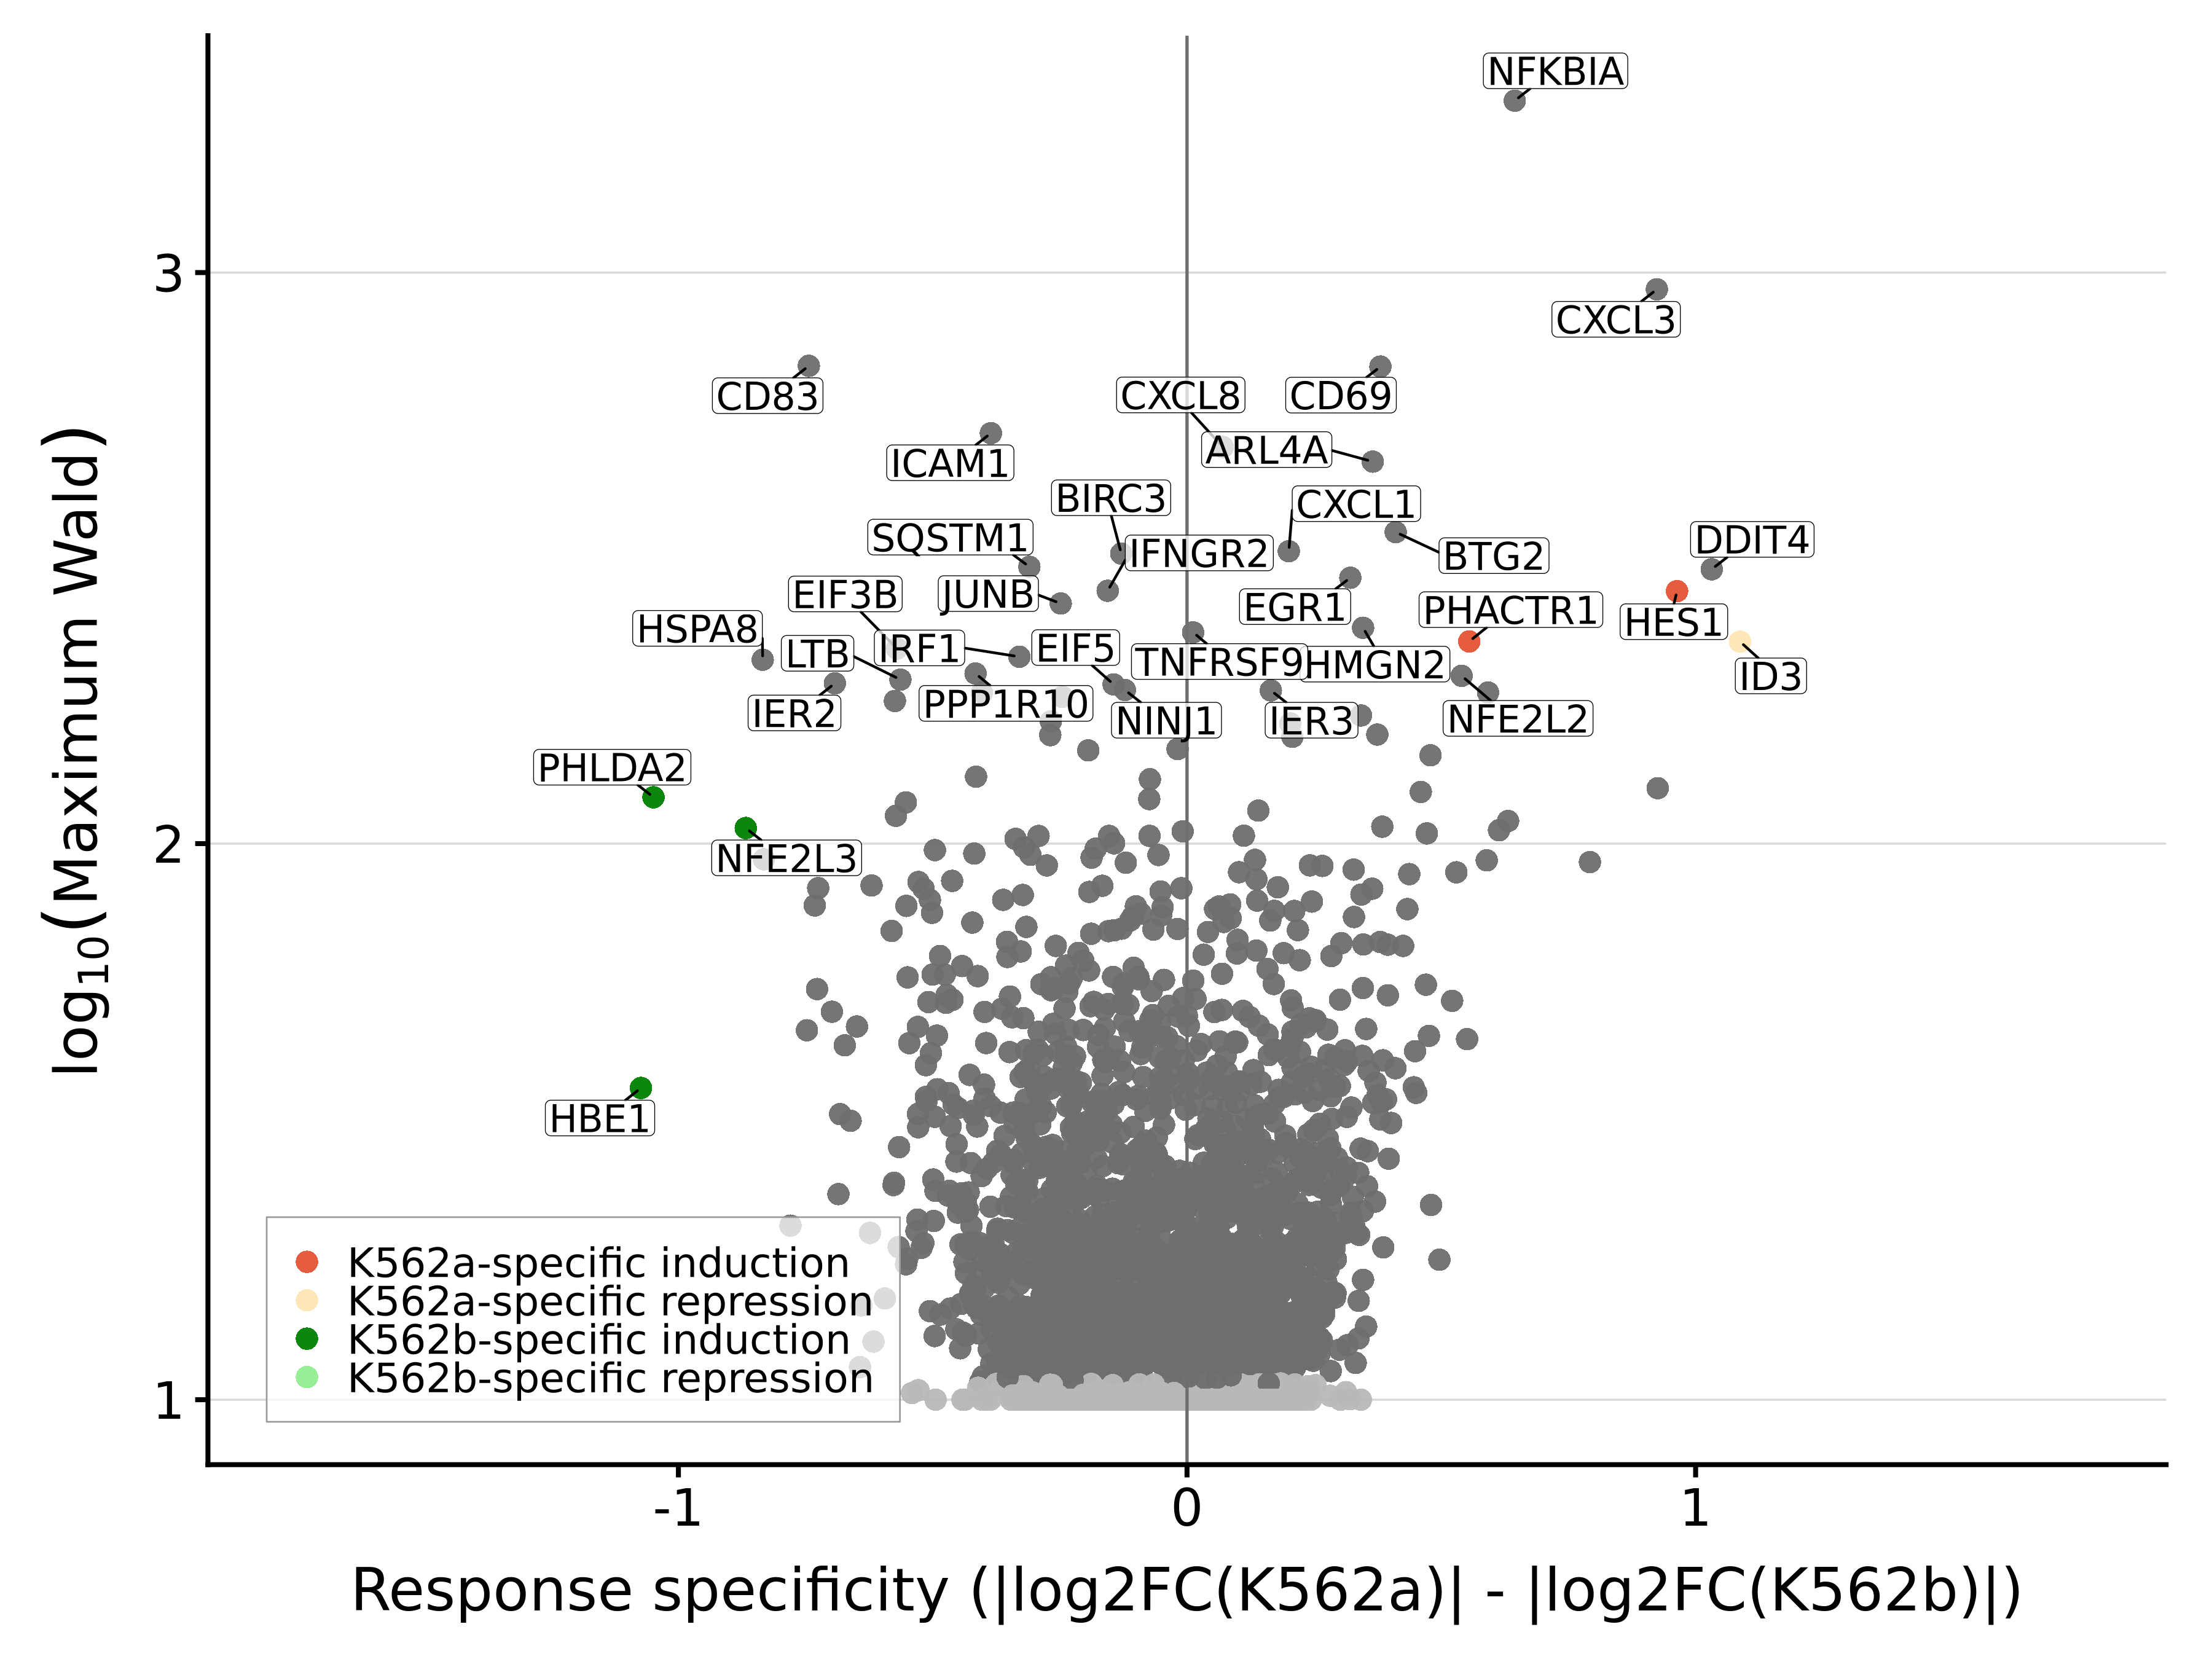

In [125]:
combined <- make_combined_from_pc_df(pc_df, 
                                     query_cell_type_1 = "K562a", 
                                     query_cell_type_2 = "K562b", 
                                     qval_fun = pmin,
                                     keep_only_common = FALSE,
                                     fill_missing = TRUE)

# combined %>% select(waldStat_1, waldStat_2, qval, log2FC_t1, log2FC_t2) %>% arrange(desc(waldStat_1))
combined = combined %>% mutate(qval = pmin(pvalue_1, pvalue_2, na.rm = TRUE))

# options(repr.plot.width = 10, repr.plot.height = 8.75, repr.plot.res = 300)
options(repr.plot.width = 12, repr.plot.height = 9, repr.plot.res = 300)

dyn_thresh  <- 1
flat_thresh <- 0.5

p <- plot_association_volcano(
  # combined %>% filter(qval < 0.05),
  combined,
  require_fdr      = FALSE,  # set TRUE for strict gating
  fdr_thresh       = 0.01,
  dyn_thresh_condA  = dyn_thresh,
  flat_thresh_condA = flat_thresh,
  dyn_thresh_condB  = dyn_thresh,
  flat_thresh_condB = flat_thresh,

  condition_key = c(
    condA = "K562a",
    condB = "K562b"
  ),
  wald_mode = 'max',
    
  x_lim = c(-1.75, 1.75),
  y_lim = c(10, 2000),
  label_top_wald = 30,
  label_top_condA = 20,
  label_top_condB = 20,
  label_size = 5.2,
  axis_title_size = 23,
  axis_text_size  = 20,
  legend_text_size = 16,
  point_size = 3.5,
    
  # legend placement inside bottom-left
  legend_pos  = c(0.03, 0.03),
  legend_just = c(0, 0),
    
  # ggrepel tuning
  repel_force = 1.4,
  repel_box_padding = 0.25,
  repel_point_padding = 0.10,
  repel_max_overlaps = Inf,
  repel_seed = 7,
  # save_prefix = "THP1vsK562_ResponseSpecificityVolcanoPlot"
)
p

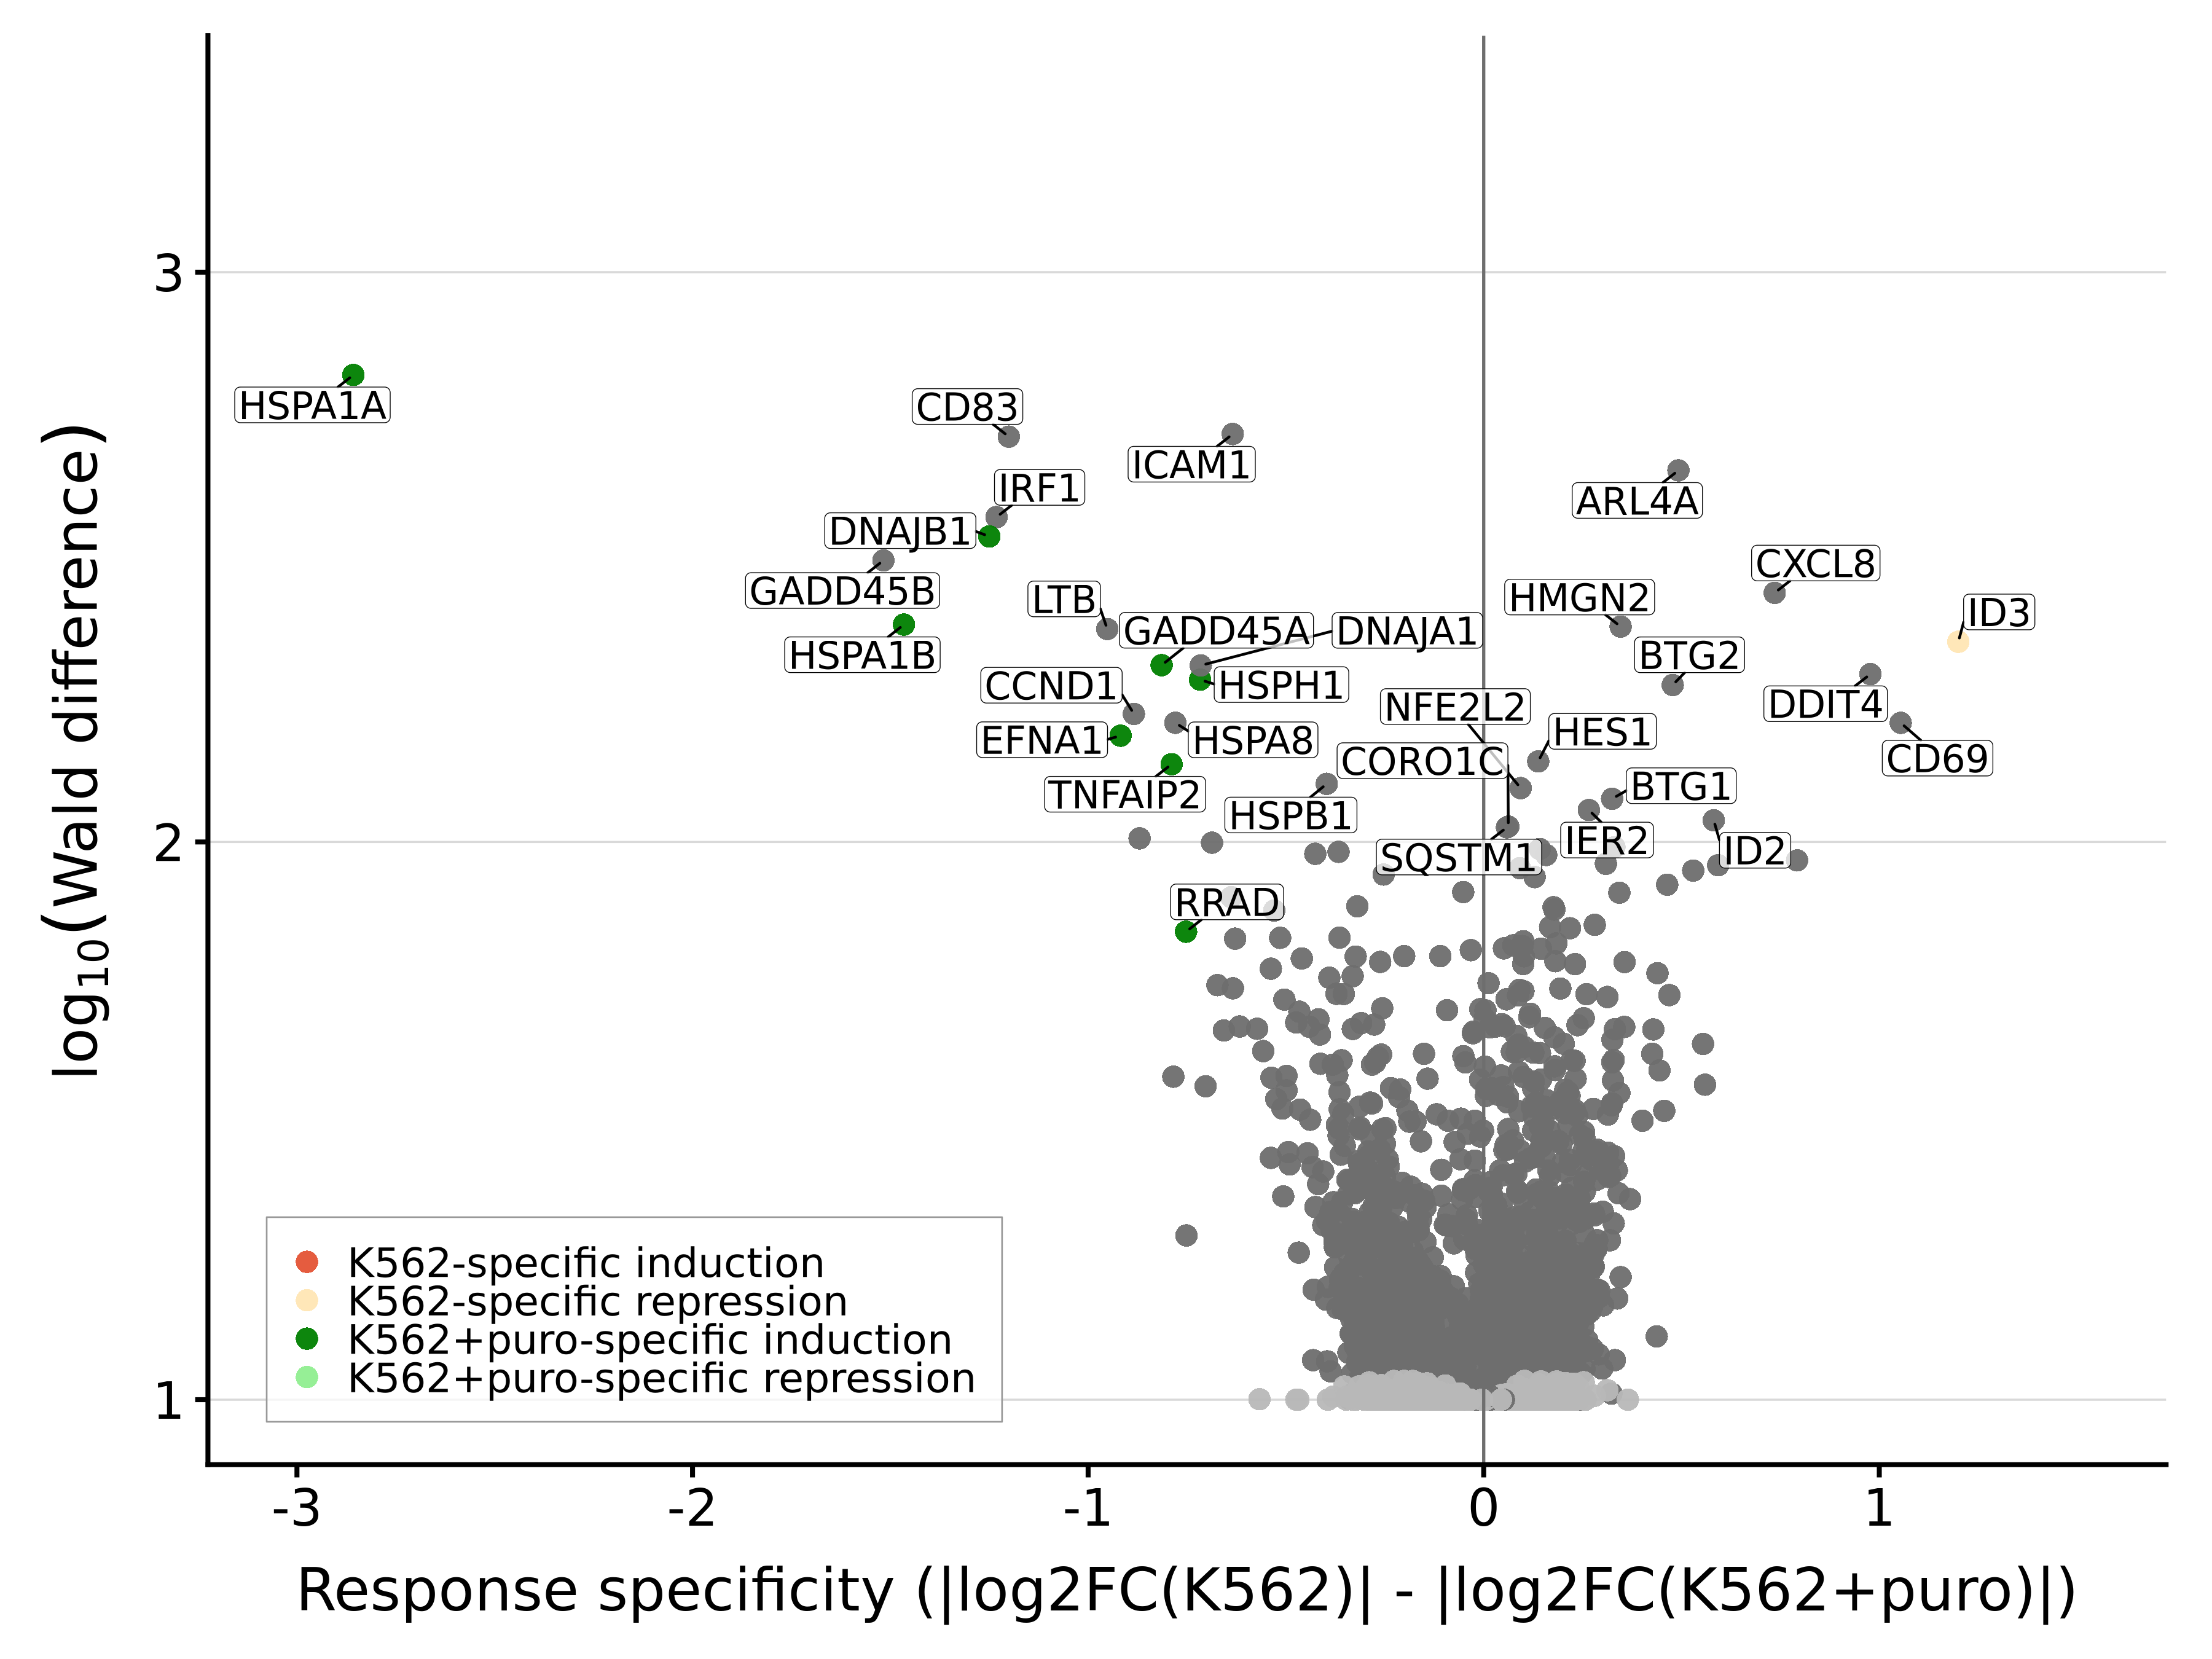

In [126]:
combined <- make_combined_from_pc_df(pc_df, 
                                     query_cell_type_1 = "K562a", 
                                     query_cell_type_2 = "K562_puro", 
                                     qval_fun = pmin,
                                     keep_only_common = FALSE,
                                     fill_missing = TRUE)

# combined %>% select(waldStat_1, waldStat_2, qval, log2FC_t1, log2FC_t2) %>% arrange(desc(waldStat_1))
combined = combined %>% mutate(qval = pmin(pvalue_1, pvalue_2, na.rm = TRUE))

# options(repr.plot.width = 10, repr.plot.height = 8.75, repr.plot.res = 300)
options(repr.plot.width = 12, repr.plot.height = 9, repr.plot.res = 300)

dyn_thresh  <- 1
flat_thresh <- 0.5

p <- plot_association_volcano(
  combined %>% filter(qval < 0.05),
  require_fdr      = FALSE,  # set TRUE for strict gating
  fdr_thresh       = 0.01,
  dyn_thresh_condA  = dyn_thresh,
  flat_thresh_condA = flat_thresh,
  dyn_thresh_condB  = dyn_thresh,
  flat_thresh_condB = flat_thresh,

  condition_key = c(
    condA = "K562",
    condB = "K562+puro"
  ),
  wald_mode = 'difference',
  x_lim = c(-3, 1.5),
  y_lim = c(10, 2000),
  label_top_wald = 30,
  label_top_condA = 20,
  label_top_condB = 20,
  label_size = 5.2,
  axis_title_size = 23,
  axis_text_size  = 20,
  legend_text_size = 16,
  point_size = 3.5,
  # legend placement inside bottom-left
  legend_pos  = c(0.03, 0.03),
  legend_just = c(0, 0),
  # ggrepel tuning
  repel_force = 1.4,
  repel_box_padding = 0.25,
  repel_point_padding = 0.10,
  repel_max_overlaps = Inf,
  repel_seed = 7,
  # save_prefix = "THP1vsK562_ResponseSpecificityVolcanoPlot"
)
p